# 01 · Data audit

**Purpose:** understand the data before modelling. What do we have, how complete is it, and what limitations must the write-up mention?

| Part | Data | Status |
|---|---|---|
| A | EPC register: social rented homes in England (the homes we will **score**) | ✅ |
| B | Geography: LSOA / MSOA / local authority | ✅ |
| C | English Housing Survey (the homes we will **train** on) | ⏳ awaiting UK Data Service access |

Inputs are built by the pipeline (`src/ingest/*`, `src/features/epc.py`, `src/geo/boundaries.py`). This notebook only reads them.

In [1]:
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SOCIAL = (ROOT / "data/processed/epc_social.parquet").as_posix()
GEO = ROOT / "data/processed/geo"

con = duckdb.connect()
con.sql(f"create or replace view social as select * from read_parquet('{SOCIAL}')")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ORANGE = "#D85A30"


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()

## A. EPC: social rented homes

The cleaned table keeps **the latest certificate per property (UPRN)** in England, then keeps it only if that latest certificate says *rented (social)*. A home that was social but has since been sold therefore drops out.

In [2]:
q('''
select count(*)                                            as homes,
       count(lsoa21cd)                                     as matched_to_lsoa,
       round(100.0 * count(lsoa21cd) / count(*), 2)        as pct_matched,
       count(distinct msoa21cd)                            as msoas,
       count(distinct lad24cd)                             as local_authorities,
       round(median(cert_age_years), 1)                    as median_cert_age_yrs
from social
''')

,homes,matched_to_lsoa,pct_matched,msoas,local_authorities,median_cert_age_yrs
0,2855846,2855271,99.98,6857,296,4.4


### How old are the certificates?

Each home is described by its *most recent* certificate, which may be years old. Older certificates may not reflect later retrofit work, so this is a limitation to report.

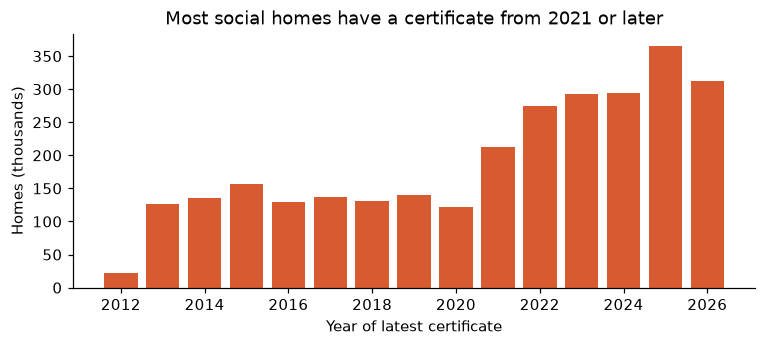

61% of homes have a certificate lodged in 2021 or later


In [3]:
ages = q("select year(lodgement_date) as year, count(*) as homes from social group by 1 order by 1")
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(ages.year, ages.homes / 1000, color=ORANGE)
ax.set(title="Most social homes have a certificate from 2021 or later", xlabel="Year of latest certificate", ylabel="Homes (thousands)")
plt.show()
share_recent = ages.loc[ages.year >= 2021, "homes"].sum() / ages.homes.sum()
print(f"{share_recent:.0%} of homes have a certificate lodged in 2021 or later")

### What are the homes like?

These are the **harmonised features**: coarse categories chosen so they can be matched to English Housing Survey variables. The parsing rules are in `src/features/epc.py` and are unit-tested in `tests/test_epc_features.py`.

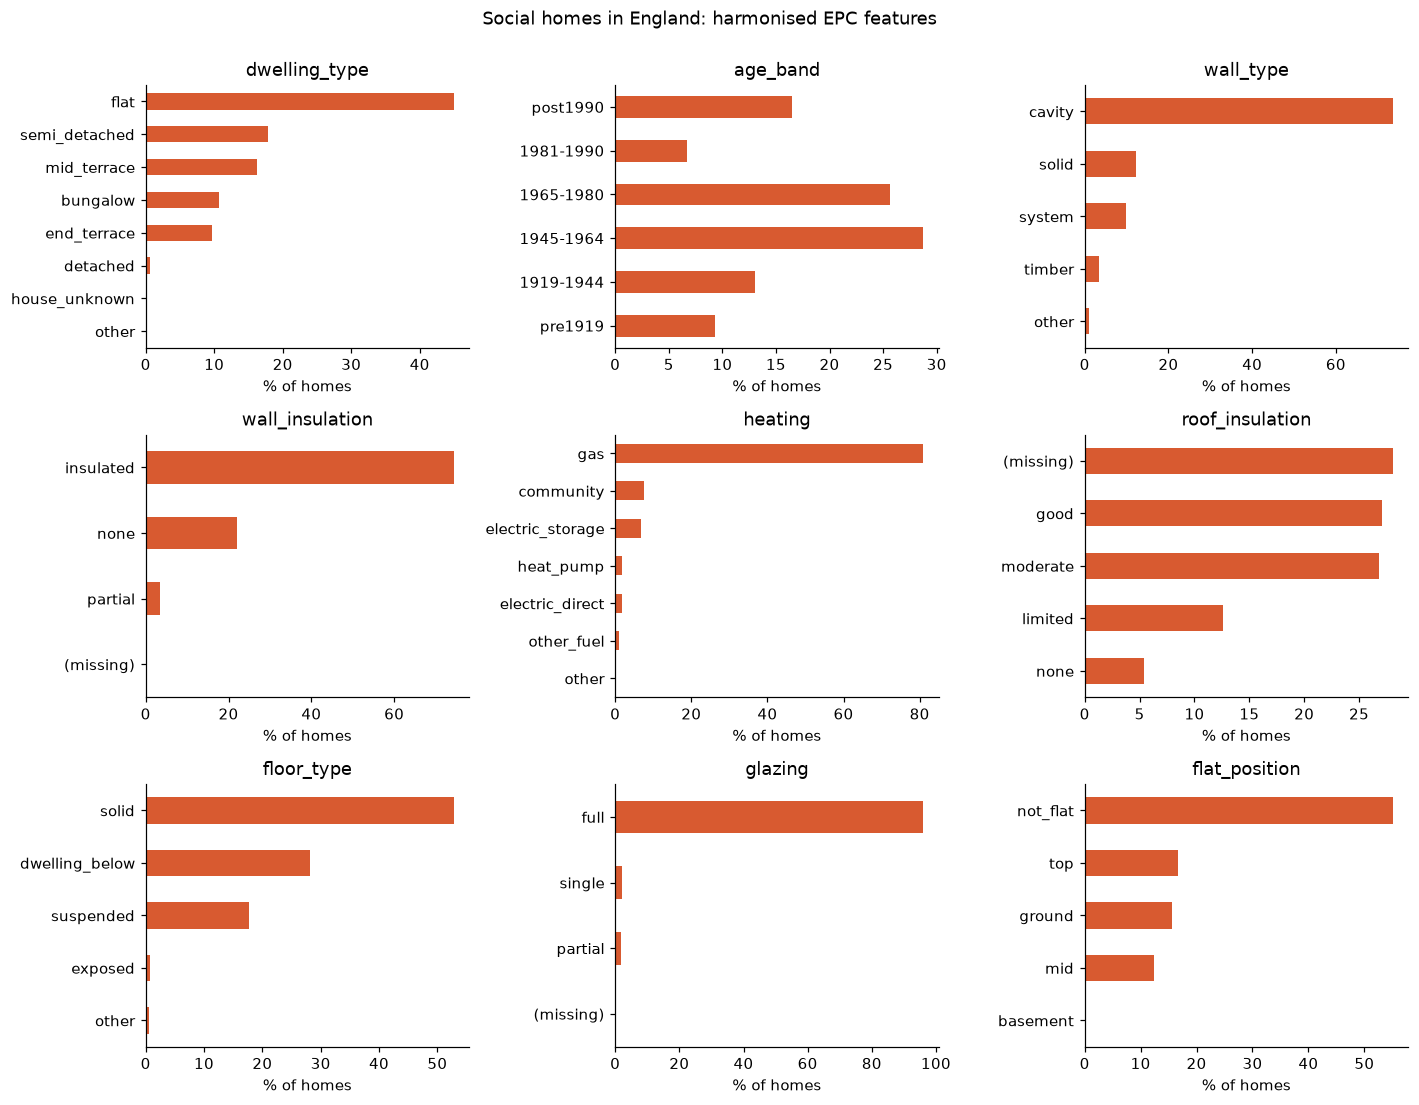

In [4]:
features = ["dwelling_type", "age_band", "wall_type", "wall_insulation", "heating",
            "roof_insulation", "floor_type", "glazing", "flat_position"]
orders = {"age_band": ["pre1919", "1919-1944", "1945-1964", "1965-1980", "1981-1990", "post1990"]}

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.flat, features):
    d = q(f"select coalesce({col}, '(missing)') as v, count(*) as n from social group by 1").set_index("v")["n"]
    d = d.reindex([o for o in orders[col] if o in d.index]) if col in orders else d.sort_values()
    (d / d.sum() * 100).plot.barh(ax=ax, color=ORANGE)
    ax.set(title=col, xlabel="% of homes", ylabel="")
fig.suptitle("Social homes in England: harmonised EPC features", y=1.0)
fig.tight_layout()
plt.show()

### Energy efficiency

SAP score runs from 1 to 100+ (higher is more efficient). Scores above 100 occur when solar panels export energy. They're rare, so cap them at 100 for modelling.

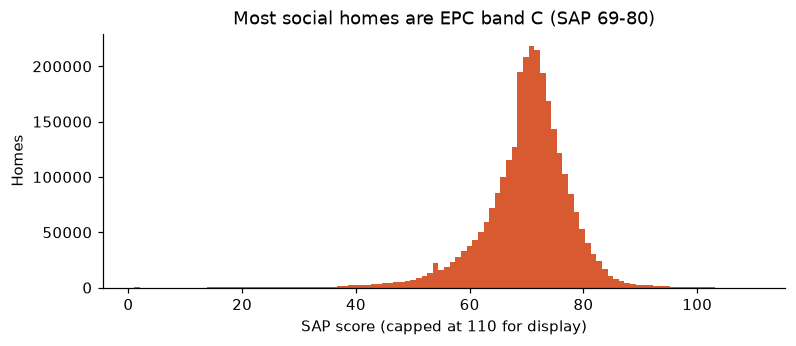

,epc_band,homes,pct
0,A,10106,0.4
1,B,148946,5.2
2,C,1772015,62.0
3,D,809310,28.3
4,E,101912,3.6
5,F,11300,0.4
6,G,2257,0.1


In [5]:
sap = q("select sap_score from social where sap_score is not null")
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sap.sap_score.clip(upper=110), bins=110, color=ORANGE)
ax.set(title="Most social homes are EPC band C (SAP 69-80)", xlabel="SAP score (capped at 110 for display)", ylabel="Homes")
plt.show()
q("select epc_band, count(*) as homes, round(100.0 * count(*) / sum(count(*)) over (), 1) as pct from social group by 1 order by 1")

### Data quality checks

In [6]:
q('''
select
  count(*) filter (where sap_score > 100)                         as sap_over_100,
  count(*) filter (where floor_area_m2 is null)                   as floor_area_missing,
  count(*) filter (where wall_insulation is null)                 as wall_insulation_unknown,
  count(*) filter (where roof_type <> 'dwelling_above' and roof_insulation is null) as roof_insulation_unknown,
  count(*) filter (where heating = 'other')                       as heating_unparsed,
  count(*) filter (where lsoa21cd is null)                        as no_lsoa
from social
''').T.rename(columns={0: "homes"})

,homes
sap_over_100,1014
floor_area_missing,413
wall_insulation_unknown,513
roof_insulation_unknown,6761
heating_unparsed,19
no_lsoa,575


## B. Geography

MSOA is the default small-area level (decided 2026-11-09): every MSOA in England has social homes, and very few have under 10.

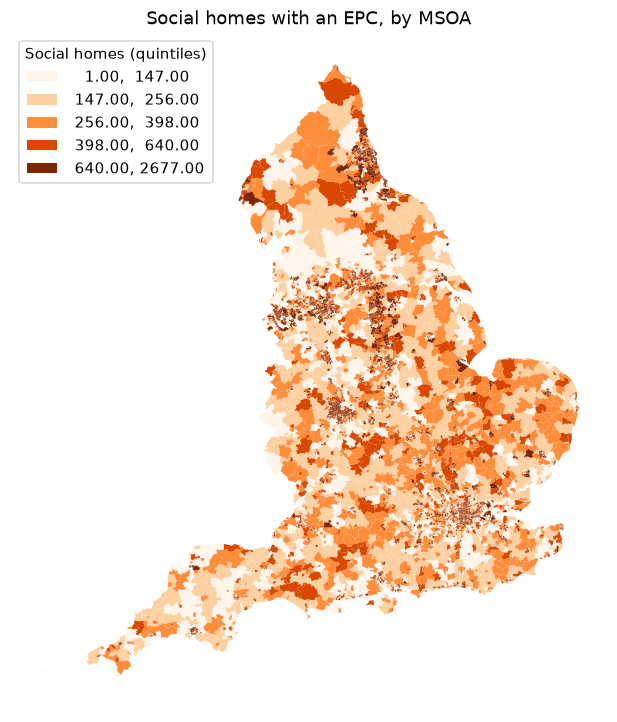

count    6856.0
mean      416.0
std       339.0
min         1.0
25%       175.0
50%       320.0
75%       562.0
max      2677.0
Name: homes, dtype: float64


In [7]:
per_msoa = q("select msoa21cd, count(*) as homes from social where msoa21cd is not null group by 1")
msoa = gpd.read_file(GEO / "msoa_england.gpkg").merge(per_msoa, on="msoa21cd", how="left")

fig, ax = plt.subplots(figsize=(7, 8))
msoa.plot(column="homes", ax=ax, cmap="Oranges", scheme="quantiles", k=5, legend=True,
          legend_kwds={"title": "Social homes (quintiles)", "loc": "upper left"}, linewidth=0)
ax.set_axis_off()
ax.set_title("Social homes with an EPC, by MSOA")
plt.show()
print(msoa.homes.describe().round(0))

## C. English Housing Survey: published damp tables

Home-level survey microdata wasn't available (the UK Data Service declined access), so the model is calibrated to the
survey's **published** damp tables (`src/ingest/ehs_tables.py`):

- **DA5101:** damp by dwelling age, type, floor area and occupancy
- **DA5102:** damp by area type, deprivation decile and region

One sheet per year from 2008, but only **2022–2024** split out social renting.

In [8]:
rates = pd.read_parquet(ROOT / "data/interim/ehs_tables/damp_rates.parquet")
social = rates[(rates.tenure == "social_rented") & (rates.damp_type == "any")]
print(f"{len(rates):,} published rates · years {sorted(int(y) for y in rates.year.unique())}")
print(f"Social rented, any damp: {len(social)} rates, {social.rate.isna().sum()} suppressed by the survey (too few cases)")
social.pivot_table(index=["table", "breakdown"], columns="year", values="rate", aggfunc="count")

2,688 published rates · years [2022, 2023, 2024]
Social rented, any damp: 168 rates, 12 suppressed by the survey (too few cases)


year                             2022  2023  2024
table  breakdown                                 
DA5101 dwelling age                 6     6     6
       dwelling type               12    12    12
       occupancy status             2     2     2
       total usable floor area      6     6     6
DA5102 area type                    7     8     8
       deprived local areas         7     9     9
       government office region    10    10    10

In [9]:
# The national total row ("all dwellings") sits under the last breakdown of each table, so select it by category
overall = social[(social.table == "DA5101") & (social.category == "all dwellings")].groupby("year").rate.first()
print("Social rented homes with damp, by survey year:", {int(y): round(r, 1) for y, r in overall.items()})

Social rented homes with damp, by survey year: {2022: 5.4, 2023: 6.9, 2024: 6.9}


## Findings

- **2.86m social homes** in England have an EPC; 99.98% are matched to neighbourhoods. Coverage is roughly 70% of the social
  stock.
- Features are well populated after parsing (under 0.1% unknown, except roof insulation where depth isn't recorded).
- **74% of pre-1919 social homes have uninsulated walls** (22% overall); 4% of social homes are rated E–G.
- The survey's published damp rates for social homes are consistent in 2023 and 2024 (6.9% both years); 2022 (5.4%) is
  partly modelled and is excluded. These rates drive the model in `02_model.ipynb`.